# Exploratory analysis: Sales & Revenue Analytics

**All data in this notebook is synthetic** (generated with `python/generate_data.py`, seed 42). Findings describe the generated dataset, not any real business.

Business rules (see `docs/business_rules.md`): revenue, cost, profit, orders, customers, margin and AOV use **Completed** orders only; revenue is net of discount; amounts are in INR.

Sections: 1 Data load and quality · 2 Headline KPIs · 3 Trend and seasonality · 4 Where the money is made (region, category, product) · 5 Discounts and margin · 6 Customers · 7 Takeaways.

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "processed").exists())
sys.path.insert(0, str(ROOT / "python"))
import kpi_definitions as kpi

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#E5E7EB", "axes.axisbelow": True})
BLUE, GREEN, ORANGE, PURPLE, PINK, RED = "#1D4ED8", "#15803D", "#C2410C", "#7C3AED", "#DB2777", "#B91C1C"
CAT = {"Technology": BLUE, "Furniture": ORANGE, "Office Supplies": PURPLE, "Home & Kitchen": GREEN, "Apparel": PINK}

tables = kpi.load_processed(ROOT / "data" / "processed")
df = kpi.enrich(tables["fact_sales"], tables)
done = df[df.order_status == "Completed"]
print({k: f"{len(v):,} rows" for k, v in tables.items()})

{'regions': '22 rows', 'products': '69 rows', 'customers': '2,200 rows', 'orders': '16,990 rows', 'order_items': '31,540 rows', 'dim_date': '731 rows', 'fact_sales': '31,540 rows'}


## 1. Data quality: what the cleaning step found

In [2]:
log = pd.read_csv(ROOT / "data" / "processed" / "cleaning_log.csv")
log[log.rows_affected > 0][["rule_id", "table", "action", "rows_affected", "description"]].reset_index(drop=True)

,rule_id,table,action,rows_affected,description
0,P2,products,repaired,3,Trim / collapse whitespace in product_name
1,P1,products,repaired,4,Standardise category spelling / case / whitesp...
2,C1,customers,dropped,7,Exact duplicate customer rows
3,C4,customers,repaired,22,Trim / collapse whitespace in customer_name
4,C2,customers,repaired,110,Standardise segment spelling / case / whitespace
5,C3,customers,repaired,22,Missing segment set to 'Unknown' (kept: custom...
6,O1,orders,dropped,68,Exact duplicate order rows
7,O2a,orders,repaired,511,order_date in dd/mm/yyyy or dd-Mon-yyyy format...
8,O2b,orders,repaired,341,ship_date in dd/mm/yyyy or dd-Mon-yyyy format ...
9,O3,orders,repaired,682,Standardise order_status spelling / case / whi...


In [3]:
rej = pd.read_csv(ROOT / "data" / "processed" / "rejected_rows.csv")
print(f"Rows quarantined (never silently dropped): {len(rej):,}")
rej.groupby(["table", "rule_id"]).size().rename("rows").reset_index()

Rows quarantined (never silently dropped): 258


,table,rule_id,rows
0,order_items,I2,48
1,order_items,I3,32
2,order_items,I6,16
3,order_items,I7,32
4,order_items,I8,32
5,order_items,I9,45
6,orders,O5a,26
7,orders,O8,27


Every defect injected into the raw files was found by exactly one rule (`python/validate_data.py` asserts this against `data/raw/defect_manifest.json`). Duplicate rows are dropped; repairable values are repaired and counted; untrustworthy rows are rejected with a reason.

## 2. Headline KPIs and order-status mix

In [4]:
k = kpi.compute_kpis(df)
pd.Series({"Revenue": kpi.format_inr(k["revenue"]), "Profit": kpi.format_inr(k["profit"]), "Completed orders": f"{k['orders']:,}",
           "Customers": f"{k['customers']:,}", "Profit margin": kpi.format_pct(k["margin"]),
           "Average order value": kpi.format_inr(k["aov"], compact=False),
           "Cancellation rate": kpi.format_pct(k["cancellation_rate"]), "Return rate": kpi.format_pct(k["return_rate"])}, name="value").to_frame()

,value
Revenue,₹26.59 Cr
Profit,₹3.88 Cr
Completed orders,"15,151"
Customers,"1,858"
Profit margin,14.6%
Average order value,"₹17,547"
Cancellation rate,5.0%
Return rate,5.8%


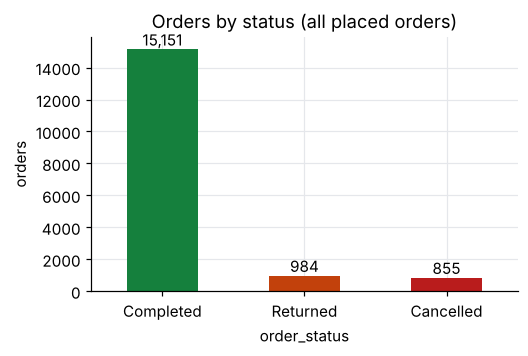

In [5]:
# Placed vs completed: why 'orders' must be defined explicitly
orders = tables["orders"]
st = orders.order_status.value_counts()
ax = st.plot.bar(color=[GREEN, ORANGE, RED], rot=0, figsize=(5, 3))
ax.set_title("Orders by status (all placed orders)"); ax.set_ylabel("orders")
for i, v in enumerate(st): ax.text(i, v, f"{v:,}", ha="center", va="bottom")
plt.show()

## 3. Trend and seasonality

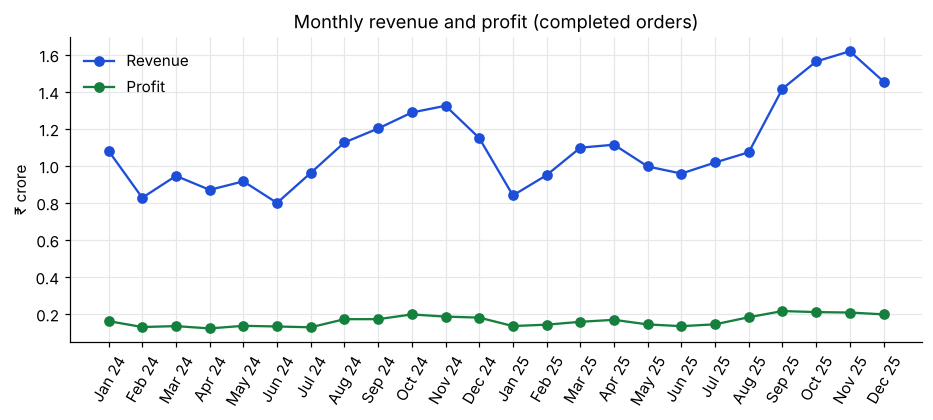

In [6]:
m = done.groupby("month_key").agg(revenue=("line_revenue", "sum"), profit=("line_profit", "sum"))
m["label"] = [pd.to_datetime(str(i), format="%Y%m").strftime("%b %y") for i in m.index]
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(m.label, m.revenue / 1e7, color=BLUE, marker="o", label="Revenue")
ax.plot(m.label, m.profit / 1e7, color=GREEN, marker="o", label="Profit")
ax.set_ylabel("₹ crore"); ax.set_title("Monthly revenue and profit (completed orders)")
plt.xticks(rotation=60); ax.legend(frameon=False); plt.show()

In [7]:
# Year-over-year growth by month and festive-season share
mm = done.groupby(["cal_year", "month_num"]).line_revenue.sum().unstack(0)
yoy = (mm[2025] / mm[2024] - 1) * 100
print("YoY revenue growth by month (%):"); print(yoy.round(1).to_string())
share = done[done.month_num.isin([10, 11])].groupby("cal_year").line_revenue.sum() / done.groupby("cal_year").line_revenue.sum()
print("\nOct-Nov share of annual revenue:", (share * 100).round(1).to_dict())

YoY revenue growth by month (%):
month_num
1    -22.3
2     14.8
3     16.1
4     28.0
5      8.8
6     19.8
7      5.8
8     -4.7
9     17.9
10    21.4
11    22.2
12    26.5

Oct-Nov share of annual revenue: {2024: 20.9, 2025: 22.6}


Revenue peaks in the Oct-Nov festive season and dips in Feb and Jun. Both years show the same shape, which is by design in the generator.

## 4. Where the money is made

In [8]:
def perf(col):
    g = done.groupby(col).agg(revenue=("line_revenue", "sum"), profit=("line_profit", "sum"), orders=("order_id", "nunique"))
    g["margin_%"] = (g.profit / g.revenue * 100).round(2); g["share_%"] = (g.revenue / g.revenue.sum() * 100).round(1)
    return g.sort_values("revenue", ascending=False)
perf("category")

,revenue,profit,orders,margin_%,share_%
category,,,,,
Technology,1.675897e+08,22481099.07,6200,13.41,63.0
Furniture,5.380507e+07,1591122.76,3424,2.96,20.2
Office Supplies,1.609094e+07,4294529.65,4441,26.69,6.1
Apparel,1.512686e+07,7060846.06,4913,46.68,5.7
Home & Kitchen,1.324803e+07,3397065.36,4949,25.64,5.0


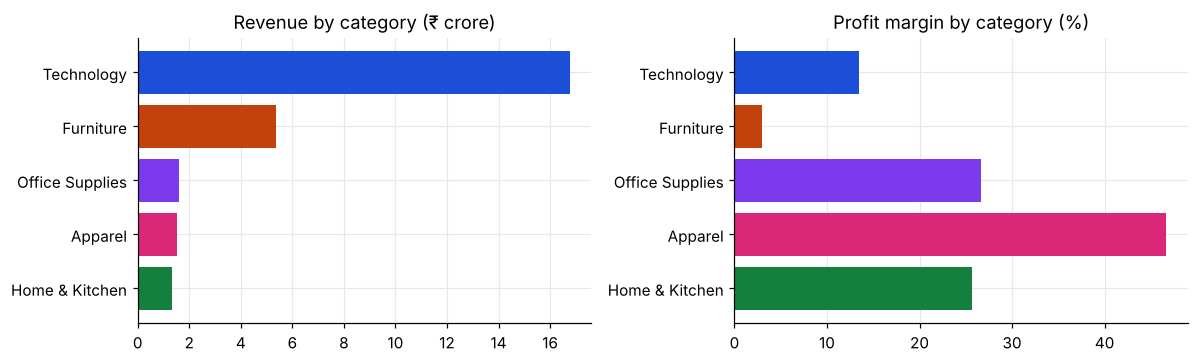

,revenue,profit,orders,margin_%,share_%
region,,,,,
West,89602051.60,13016595.42,4718,14.53,33.7
South,76107921.60,11121718.31,4389,14.61,28.6
North,54770376.55,8254478.35,3502,15.07,20.6
Central,22831906.55,3216490.37,1131,14.09,8.6
East,22548350.90,3215380.45,1411,14.26,8.5


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
c = perf("category")
axes[0].barh(c.index[::-1], c.revenue[::-1] / 1e7, color=[CAT[i] for i in c.index[::-1]]); axes[0].set_title("Revenue by category (₹ crore)")
axes[1].barh(c.index[::-1], c["margin_%"][::-1], color=[CAT[i] for i in c.index[::-1]]); axes[1].set_title("Profit margin by category (%)")
plt.tight_layout(); plt.show()
perf("region")

In [10]:
cy = done.groupby(["category", "cal_year"]).apply(lambda d: d.line_profit.sum() / d.line_revenue.sum() * 100, include_groups=False).unstack().round(2)
cy["change_pp"] = (cy[2025] - cy[2024]).round(2)
cy

cal_year,2024,2025,change_pp
category,,,
Apparel,46.59,46.75,0.16
Furniture,4.54,1.39,-3.15
Home & Kitchen,25.73,25.57,-0.16
Office Supplies,26.57,26.78,0.21
Technology,13.61,13.24,-0.37


Furniture is the margin problem: roughly a fifth of revenue at a low single-digit margin that fell further in 2025. In the generator its cost inflation (+6%) outpaces its price increase (+2%) while discounts stay deep (averaging about 13% on Furniture lines). Technology carries the profit dollars because of volume, not margin.

In [11]:
prod = done.groupby("product_name").agg(revenue=("line_revenue", "sum"), profit=("line_profit", "sum")).sort_values("revenue", ascending=False)
prod["margin_%"] = (prod.profit / prod.revenue * 100).round(1)
print("Top 5 products by revenue"); display(prod.head(5))
print("Loss-making products:"); display(prod[prod.profit < 0])

Top 5 products by revenue


,revenue,profit,margin_%
product_name,,,
Nexa Phone Pro 256GB,34981566.90,4521507.11,12.9
Aria Book Pro 16,26624075.40,3072054.84,11.5
Aria Book 14 Laptop,19728277.75,2302440.32,11.7
Lumio Edge 5G,19256933.50,2674375.77,13.9
Veloce Air 13 Ultrabook,17968490.60,1802706.47,10.0


Loss-making products:


,revenue,profit,margin_%
product_name,,,
Compact Study Table,3725130.25,-16326.96,-0.4


## 5. Discounts and margin

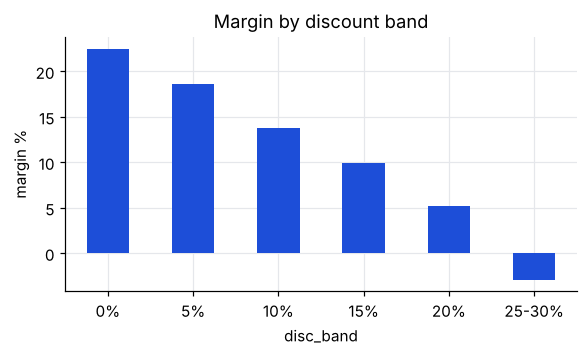

,lines,revenue,profit,margin_%
disc_band,,,,
0%,5477,65071150.00,14632248.10,22.5
5%,5956,62789994.45,11676018.15,18.6
10%,5864,57347957.70,7934046.82,13.8
15%,4676,39267829.95,3888888.80,9.9
20%,3131,23462918.40,1218406.97,5.2
25-30%,2942,17920756.70,-524945.94,-2.9


In [12]:
d = done.assign(disc_band=pd.cut(done.discount, [-0.001, 0, 0.05, 0.10, 0.15, 0.20, 0.30], labels=["0%", "5%", "10%", "15%", "20%", "25-30%"]))
band = d.groupby("disc_band", observed=True).agg(lines=("order_item_id", "count"), revenue=("line_revenue", "sum"), profit=("line_profit", "sum"))
band["margin_%"] = (band.profit / band.revenue * 100).round(1)
ax = band["margin_%"].plot.bar(color=BLUE, rot=0, figsize=(6, 3)); ax.set_title("Margin by discount band"); ax.set_ylabel("margin %")
plt.show(); band

Margin falls from about 22% on undiscounted lines to slightly negative at 25-30% off. Technology and Furniture lines discounted by more than 20% lose money on average, and Furniture is already negative above 10%. The average discount itself was unchanged between 2024 and 2025 (about 10.7%).

## 6. Customers

Top 5 customers


,,orders,revenue,profit
customer_id,customer_name,,,
C0828,Reyansh Siddiqui,167,5024778.0,560586.0
C1674,Kriti Desai,90,4118809.0,521008.0
C2153,Kavya Nair,93,3012623.0,259258.0
C0386,Aarav Mehta,97,2787961.0,376692.0
C0569,Ananya Verma,50,2612440.0,410462.0


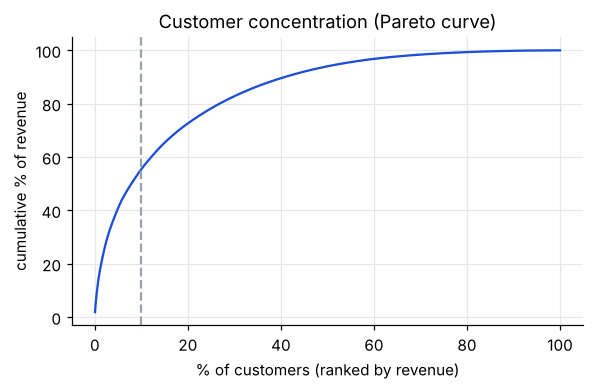

Top 5 customers: 6.6% of revenue; top 10%: 55.3%


In [13]:
cu = done.groupby(["customer_id", "customer_name"]).agg(orders=("order_id", "nunique"), revenue=("line_revenue", "sum"), profit=("line_profit", "sum")).sort_values("revenue", ascending=False)
print("Top 5 customers"); display(cu.head(5).round(0))
cum = cu.revenue.cumsum() / cu.revenue.sum() * 100
x = (pd.Series(range(1, len(cum) + 1)) / len(cum) * 100)
fig, ax = plt.subplots(figsize=(6, 3.4)); ax.plot(x, cum.values, color=BLUE)
ax.axvline(10, color="#9CA3AF", ls="--"); ax.set_xlabel("% of customers (ranked by revenue)"); ax.set_ylabel("cumulative % of revenue")
ax.set_title("Customer concentration (Pareto curve)"); plt.show()
print(f"Top 5 customers: {cu.revenue.head(5).sum() / cu.revenue.sum() * 100:.1f}% of revenue; top 10%: {cum.iloc[int(len(cum) * .1) - 1]:.1f}%")

In [14]:
seg = done.groupby("segment").agg(revenue=("line_revenue", "sum"), profit=("line_profit", "sum"), orders=("order_id", "nunique"))
seg["margin_%"] = (seg.profit / seg.revenue * 100).round(1); seg["aov"] = (seg.revenue / seg.orders).round(0)
seg.sort_values("revenue", ascending=False)

,revenue,profit,orders,margin_%,aov
segment,,,,,
Corporate,1.409715e+08,17176564.04,3946,12.2,35725.0
Consumer,9.239613e+07,16727760.11,8851,18.1,10439.0
Small Business,2.763803e+07,4071230.26,1975,14.7,13994.0
Unknown,4.854986e+06,849108.49,379,17.5,12810.0


## 7. Takeaways (synthetic data)

1. Revenue grew about 13% year over year but margin slipped slightly: Furniture costs rose faster than its prices while average discounts stayed flat.
2. West and South generate roughly 60% of revenue; regional margins are close, so regional gaps are volume gaps.
3. Technology dominates revenue and profit dollars; Furniture is the thin-margin drag; Apparel has the highest margin but small revenue.
4. Revenue concentration across individual customers is moderate (top 5 about 7%), but the top 10% of customers deliver over half of revenue.
5. Corporate customers bring the largest revenue share at a lower margin than Consumers.

All of these are reproduced as live measures in the Power BI report (`powerbi/DAX_Measures.md`) and in `streamlit_app/app.py`.